# Fit IM7 Measurements in the zmx Format

This example shows how impedance spectra measured with the IM7 are fitted. [Zahner Lab](https://zahner.de) saves IM7 measurements as *.zmx* files.

A *.zmx* file can contain more than one impedance spectrum. With PAD4 cards, the voltage of every PAD4 channel is measured at the same time as the voltage of the cell. This gives one impedance for the cell and one impedance for each PAD4 channel. Typical applications are the single cells of a battery stack or a fuel cell stack.

The measurement *randles_pad42.zmx* in this example was made with two PAD4 cards. It contains nine impedances: the cell and eight PAD4 channels. All channels measured the same test circuit, so all impedances are almost equal. The same equivalent circuit model is fitted to every impedance.

**For .zmx files, a [Zahner Analysis](https://zahner.de/products-details/software/Zahner-Analysis) which supports the IM7 file formats is required.** The *.zmx* file is read in Python with the package [zahner_link](https://pypi.org/project/zahner-link/), which is installed together with *zahner_analysis*.

In [1]:
from zahner_analysis.analysis_tools.eis_fitting import EisFitting, EisFittingPlotter
from zahner_analysis.file_import.impedance_model_import import IsfxModelImport
from zahner_analysis.file_import.zmx_import import ZmxImport
import matplotlib.pyplot as plt
import re

# Import the circuit model and the measurement data

The model is loaded with the class [IsfxModelImport](https://doc.zahner.de/zahner_analysis/file_import/index.html#zahner_analysis.file_import.impedance_model_import.IsfxModelImport), as in the other examples.

The *.zmx* file is loaded with the class [ZmxImport](https://doc.zahner.de/zahner_analysis/file_import/index.html#zahner_analysis.file_import.zmx_import.ZmxImport). It contains one [ZmxImpedance](https://doc.zahner.de/zahner_analysis/file_import/index.html#zahner_analysis.file_import.zmx_import.ZmxImpedance) object for each impedance of the measurement.

**Why is there a separate class for a single impedance?** A *.zmx* file can contain several impedances, but the fit and the plotting functions always work on exactly one spectrum. A ZmxImpedance object therefore represents one impedance with the same getters as an *.ism* file, and it keeps a reference to its file, because the Zahner Analysis needs the whole *.zmx* file together with the name of the impedance to fit.

Each impedance has two names:
* The **dimension name** consists of the numerator and the denominator of the impedance, for example *padx[1].ch1/current* for the voltage of channel 1 of the first PAD4 card divided by the current of the cell. The Zahner Analysis shows this name if nobody named the impedance.
* The **name** is the impedance name stored in the file. Zahner Lab stores the signal paths of the impedance here, unless the user gave the impedance a name. This name is sent to the Zahner Analysis to select the impedance for the fit.

In [2]:
impedanceCircuitModel = IsfxModelImport("randles.isfx")
zmxData = ZmxImport("randles_pad42.zmx")

print(impedanceCircuitModel)

for impedance in zmxData.getImpedances():
    print(f"{impedance.getDimensionName():22} {impedance.getName()}")

resistor : R2
      R:  4.990e+01 Ω        fixed: False
resistor : R1
      R:  2.459e+02 Ω        fixed: False
resistor : R0
      R:  6.629e+02 Ω        fixed: False
capacitor : C1
      C:  3.185e-07 F        fixed: False
capacitor : C0
      C:  4.757e-06 F        fixed: False

padx[1].ch1/current    43044.CH1~43044.ADC1/2557874741.POT.I~43043.PAD_I
padx[1].ch2/current    43044.CH2~43044.ADC2/2557874741.POT.I~43043.PAD_I
padx[1].ch3/current    43044.CH3~43044.ADC3/2557874741.POT.I~43043.PAD_I
padx[1].ch4/current    43044.CH4~43044.ADC4/2557874741.POT.I~43043.PAD_I
padx[2].ch1/current    43045.CH1~43045.ADC1/2557874741.POT.I~43043.PAD_I
padx[2].ch2/current    43045.CH2~43045.ADC2/2557874741.POT.I~43043.PAD_I
padx[2].ch3/current    43045.CH3~43045.ADC3/2557874741.POT.I~43043.PAD_I
padx[2].ch4/current    43045.CH4~43045.ADC4/2557874741.POT.I~43043.PAD_I
voltage/current        2557874741.POT.U~43043.PAD_U/2557874741.POT.I~43043.PAD_I


# Select a single impedance

A single impedance can be selected with the method [getImpedance()](https://doc.zahner.de/zahner_analysis/file_import/index.html#zahner_analysis.file_import.zmx_import.ZmxImport.getImpedance) or with the []-operator. Both the name and the dimension name can be used. Without a name, the impedance of the cell is returned.

A [ZmxImpedance](https://doc.zahner.de/zahner_analysis/file_import/index.html#zahner_analysis.file_import.zmx_import.ZmxImpedance) object has the same getters for frequency, impedance and phase as the [IsmImport](https://doc.zahner.de/zahner_analysis/file_import/index.html#zahner_analysis.file_import.ism_import.IsmImport) class. Like with *.ism* files, only the largest range without overlapping frequencies is returned by default.

In [3]:
cellImpedance = zmxData.getImpedance()
padImpedance = zmxData["padx[1].ch1/current"]

print(f"Cell: {cellImpedance.getDimensionName()}")
print(f"PAD4 channel: {padImpedance.getDimensionName()}")
print(f"Number of frequencies: {len(padImpedance.getFrequencyArray())}")
print(
    f"Frequency range: {min(padImpedance.getFrequencyArray())} Hz to {max(padImpedance.getFrequencyArray())} Hz"
)
print(f"Tracks: {padImpedance.getTrackTypesList()}")

Cell: voltage/current
PAD4 channel: padx[1].ch1/current
Number of frequencies: 57
Frequency range: 1.0 Hz to 100000.0 Hz
Tracks: ['impedance drift', 'impedance error', 'phase', 'phase drift', 'phase error', '|impedance|']


# Create the EisFitting object

The [EisFitting](https://doc.zahner.de/zahner_analysis/analyze/index.html#zahner_analysis.analysis_tools.eis_fitting.EisFitting) object is created as in the other examples. It connects to the Zahner Analysis, or starts it if it is not running.

In [4]:
fitting = EisFitting()

# Fit the model to all impedances

The [fit()](https://doc.zahner.de/zahner_analysis/analyze/index.html#zahner_analysis.analysis_tools.eis_fitting.EisFitting.fit) method accepts a [ZmxImpedance](https://doc.zahner.de/zahner_analysis/file_import/index.html#zahner_analysis.file_import.zmx_import.ZmxImpedance) object like an *.ism* file. The whole *.zmx* file is sent to the Zahner Analysis, together with the name of the impedance as the fit parameter *ImpedanceName*. The Zahner Analysis then fits only this impedance.

If the whole [ZmxImport](https://doc.zahner.de/zahner_analysis/file_import/index.html#zahner_analysis.file_import.zmx_import.ZmxImport) object is passed to the fit, the Zahner Analysis fits the impedance of the cell.

The simulated data and the samples used for the fit are returned in the format of the input, here as *.zmx*. With the parameter *outputFormat="ism"* of the fit method, *.ism* data can be requested instead.

[getImpedanceName()](https://doc.zahner.de/zahner_analysis/analyze/index.html#zahner_analysis.analysis_tools.eis_fitting.EisFittingResult.getImpedanceName) returns the name of the fitted impedance, as the Zahner Analysis reports it.

Each fit result is saved in the folder *fit_results*, in a subfolder named after the impedance.

In [5]:
fittingResults = {}

for impedance in zmxData.getImpedances():
    fittingResult = fitting.fit(impedanceCircuitModel, impedance)
    fittingResults[impedance.getDimensionName()] = fittingResult

    print(f"Fitted impedance: {fittingResult.getImpedanceName()}")

    foldername = re.sub(r"[^A-Za-z0-9]+", "_", impedance.getDimensionName()).strip("_")
    fittingResult.save(path="fit_results", foldername=foldername)

Fitted impedance: padx[1].ch1/current
Fitted impedance: padx[1].ch2/current


Fitted impedance: padx[1].ch3/current
Fitted impedance: padx[1].ch4/current


Fitted impedance: padx[2].ch1/current
Fitted impedance: padx[2].ch2/current


Fitted impedance: padx[2].ch3/current
Fitted impedance: padx[2].ch4/current


Fitted impedance: voltage/current


# Compare the fitted parameters

The parameters of the fitted models are read with the []-operator and shown in a table. Since every channel measured the same circuit, the values differ only slightly.

In [6]:
print(
    f"{'Impedance':22} {'R0':>10} {'R1':>10} {'R2':>10} {'C0':>10} {'C1':>10} {'Error':>8}"
)

for name, fittingResult in fittingResults.items():
    fittedModel = fittingResult.getFittedModel()
    overallError = fittingResult.getFitResultJson()["overall"]["overall_error"]
    print(
        f"{name:22}"
        f" {fittedModel['R0']['R'].getValue():8.3f} Ω"
        f" {fittedModel['R1']['R'].getValue():8.3f} Ω"
        f" {fittedModel['R2']['R'].getValue():8.3f} Ω"
        f" {fittedModel['C0']['C'].getValue():10.3e}"
        f" {fittedModel['C1']['C'].getValue():10.3e}"
        f" {overallError:8.3f}"
    )

Impedance                      R0         R1         R2         C0         C1    Error
padx[1].ch1/current     662.675 Ω  245.737 Ω   50.037 Ω  4.758e-06  3.192e-07    0.986
padx[1].ch2/current     662.821 Ω  245.765 Ω   50.011 Ω  4.759e-06  3.192e-07    1.025
padx[1].ch3/current     662.737 Ω  245.772 Ω   50.013 Ω  4.758e-06  3.191e-07    1.028
padx[1].ch4/current     662.676 Ω  245.803 Ω   50.009 Ω  4.758e-06  3.191e-07    1.028
padx[2].ch1/current     662.727 Ω  245.856 Ω   49.941 Ω  4.758e-06  3.187e-07    1.040
padx[2].ch2/current     662.711 Ω  245.866 Ω   49.931 Ω  4.757e-06  3.187e-07    1.046
padx[2].ch3/current     662.757 Ω  245.861 Ω   49.920 Ω  4.757e-06  3.187e-07    1.053
padx[2].ch4/current     662.835 Ω  245.877 Ω   49.911 Ω  4.756e-06  3.186e-07    1.080
voltage/current         662.880 Ω  245.924 Ω   49.901 Ω  4.757e-06  3.185e-07    1.016


# Plot the result of one channel

The [EisFittingPlotter](https://doc.zahner.de/zahner_analysis/analyze/index.html#zahner_analysis.analysis_tools.eis_fitting.EisFittingPlotter) plots the fit result. The measured impedance of the channel is passed as *impedanceData*, so that all measured points are displayed and not only the samples used for the fit.

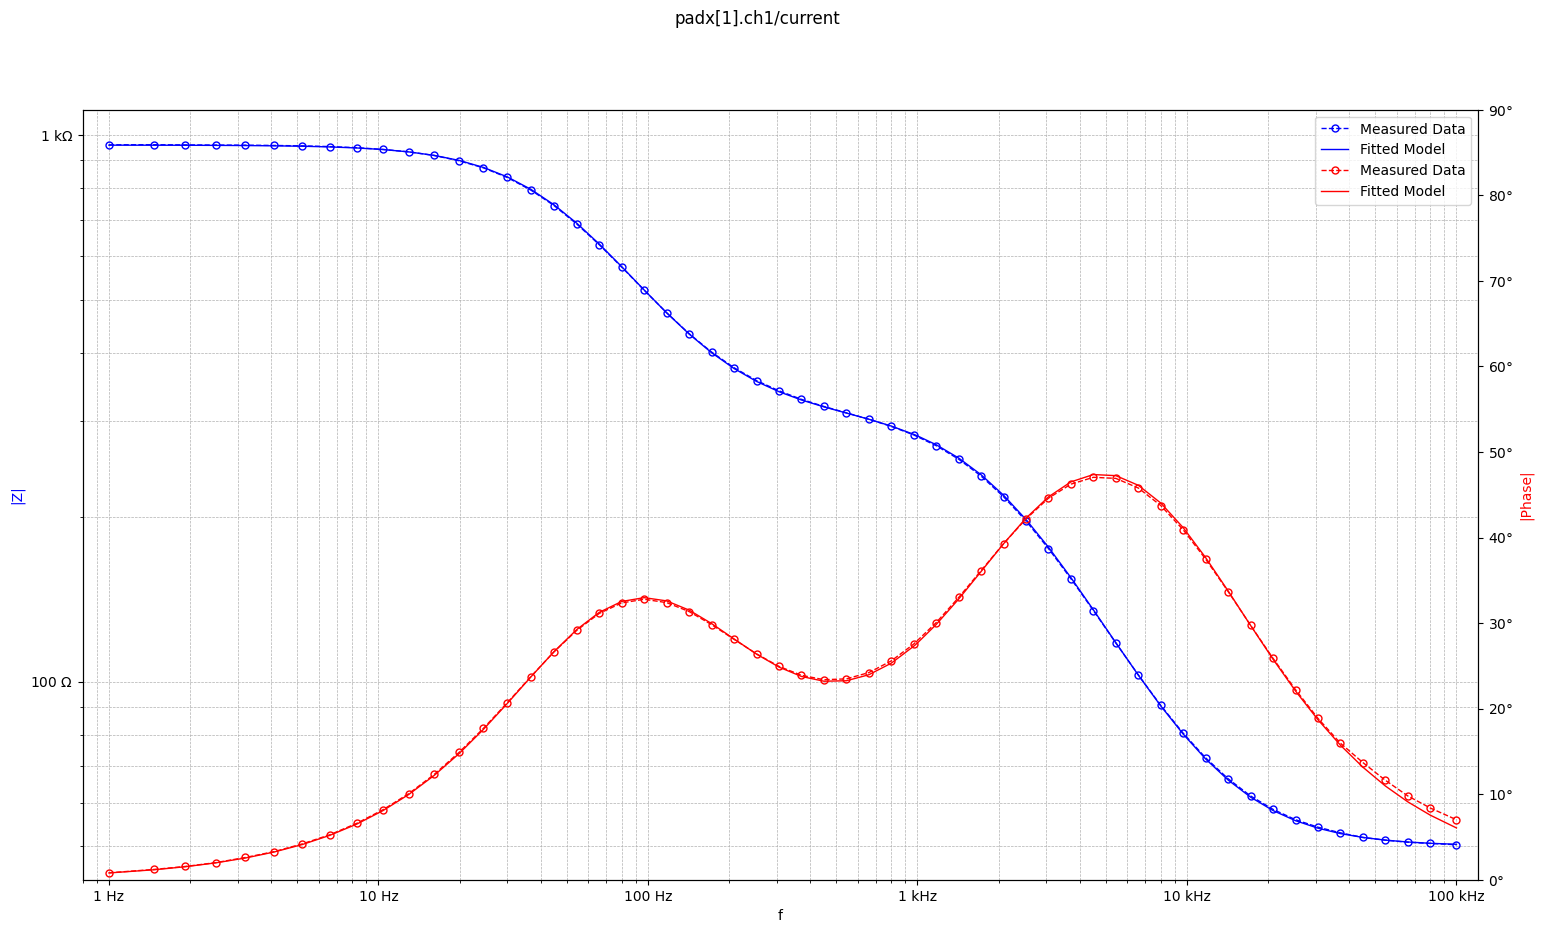

In [7]:
fig, (impedanceAxis, phaseAxis) = EisFittingPlotter.plotBode(
    fittingResults["padx[1].ch1/current"], impedanceData=padImpedance
)
impedanceAxis.legend(
    impedanceAxis.get_lines() + phaseAxis.get_lines(),
    2 * ["Measured Data", "Fitted Model"],
)
fig.suptitle("padx[1].ch1/current")
fig.set_size_inches(18, 10)
plt.show()
fig.savefig("fit_results/bode_padx_1_ch1.svg")

# Plot the results of all channels

The Nyquist plots of all nine impedances are displayed next to each other. The axes are passed to the plot method, so that each impedance is plotted in its own diagram.

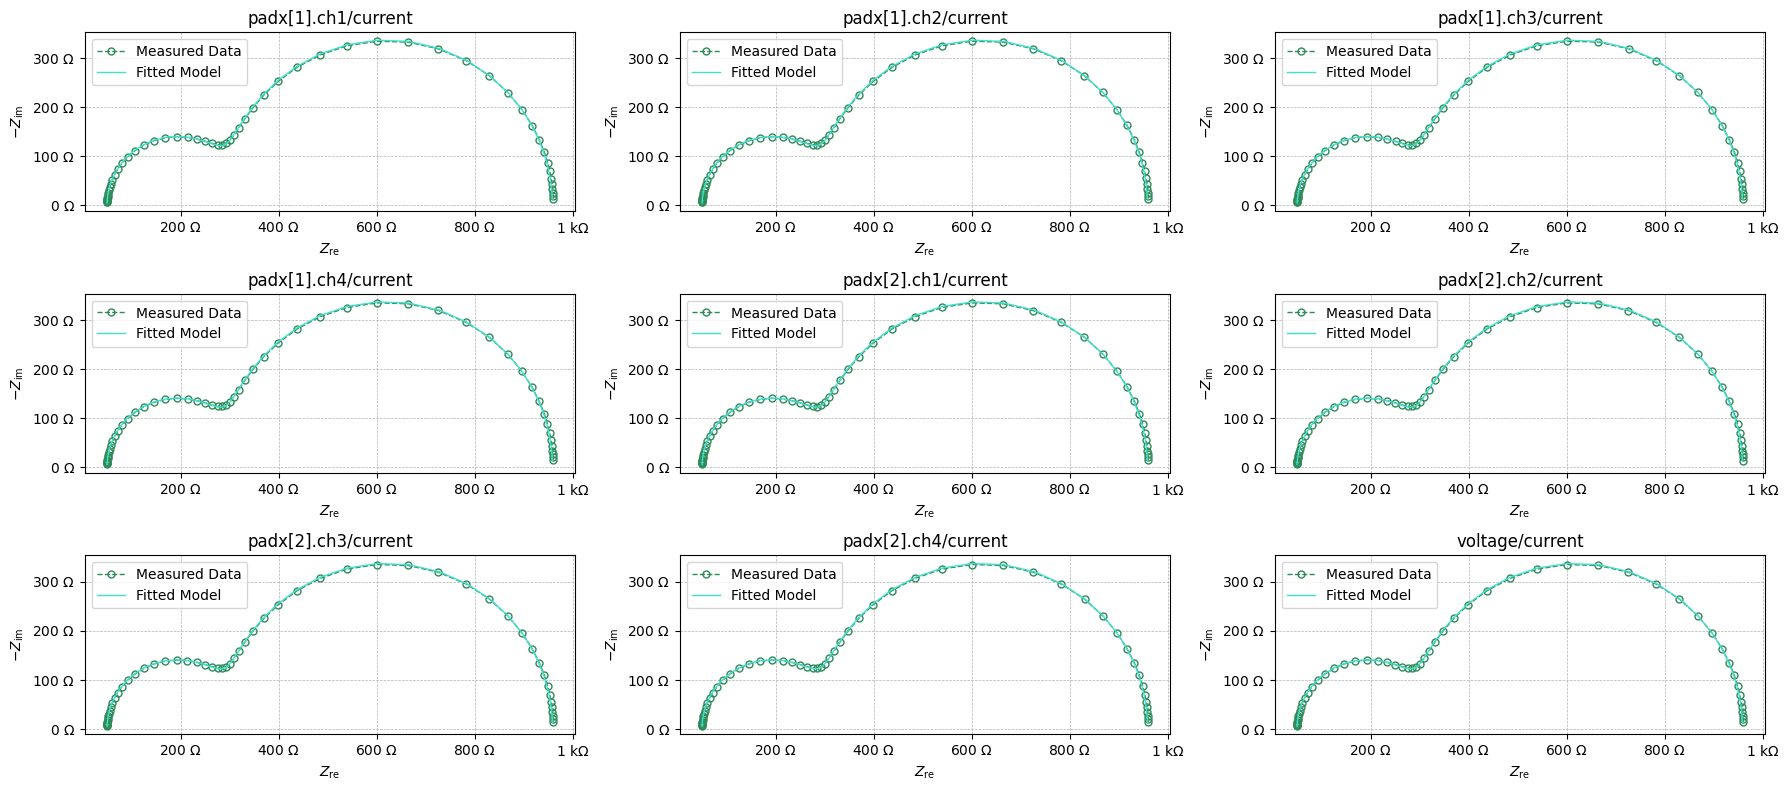

In [8]:
fig, axes = plt.subplots(3, 3)

for ax, (name, fittingResult) in zip(axes.flat, fittingResults.items()):
    EisFittingPlotter.plotNyquist(fittingResult, impedanceData=zmxData[name], ax=ax)
    ax.set_title(name)
    ax.legend(["Measured Data", "Fitted Model"])

fig.set_size_inches(18, 8)
fig.tight_layout()
plt.show()
fig.savefig("fit_results/nyquist_all_channels.svg")